# EXP-003: Label-noise contrast case (a different instability mechanism)

**Status: engineering validation / proof of concept**, same caveats as EXP-001/EXP-002.

**Purpose**: EXP-001 tested "instability" via a somewhat artificial mechanism --
injecting zero-mean Gaussian noise directly into the computed GRADIENTS. That worked
(reduce wins decisively). This notebook tests a different, more standard/realistic
noise mechanism explicitly requested as a check: **pure per-batch label noise** -- a
fraction of each batch's labels are randomly flipped, with NO drift in class means
and NO change to input variance. Genuinely nothing systematic changes about the task;
only a fraction of training labels are wrong on any given step. This is the classic
"symmetric label noise" model from the noisy-label learning literature.

**Question**: does "reduce" still win for this disturbance, confirming the earlier
finding generalizes across DIFFERENT noise-injection mechanisms (not just the one
gradient-noise construction that happened to be built first), or was gradient-noise
injection doing something mechanism-specific that label noise doesn't reproduce?


In [1]:
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

torch.set_num_threads(1)
print("torch", torch.__version__, "| numpy", np.__version__)


C:\Users\USER\anaconda3\Lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


torch 2.5.1+cpu | numpy 2.0.2


## 1. Toy task with label-noise disturbance

In [2]:
def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1))

MEAN0_BASE = np.array([-1.0, -1.0])
MEAN1_BASE = np.array([1.0, 1.0])
BASE_NOISE_SCALE = 0.5

def gen_batch(rng, flip_prob=0.0, batch_size=16):
    '''x is drawn from the TRUE class-conditional distribution (means/variance never
    change -- no drift, no input-noise increase). Only the LABEL handed to the loss
    function is corrupted, independently per sample, with probability flip_prob. This
    is standard symmetric label noise: P(x|y_true) is untouched, only P(y_observed|x)
    is corrupted. Nothing systematic about the task changes.'''
    y_true = rng.integers(0, 2, size=batch_size)
    means = np.where(y_true[:, None] == 0, MEAN0_BASE, MEAN1_BASE)
    x = means + rng.normal(scale=BASE_NOISE_SCALE, size=(batch_size, 2))
    flip_mask = rng.random(batch_size) < flip_prob
    y_observed = np.where(flip_mask, 1 - y_true, y_true)
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y_observed, dtype=torch.float32)

def grad_norm(model):
    total = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total += float((p.grad.detach() ** 2).sum())
    return total ** 0.5


## 2. Disturbance schedule

In [3]:
N_STEPS = 400
DISTURBANCE_ONSET = 200
RAMP_LEN = 40
MAX_FLIP_PROB = 0.35   # well below 0.5 (which would make labels pure noise/uninformative)
STEADY_STATE_WINDOW = 100

def _ramp(step):
    if step < DISTURBANCE_ONSET:
        return 0.0
    return min(step - DISTURBANCE_ONSET, RAMP_LEN) / RAMP_LEN

def _instant(step):
    return 1.0 if step >= DISTURBANCE_ONSET else 0.0

def label_noise_forecastable(step):
    return MAX_FLIP_PROB * _ramp(step)

def label_noise_unforecastable(step):
    return MAX_FLIP_PROB * _instant(step)

print("forecastable @190,200,210,220,240:",
      [label_noise_forecastable(s) for s in (190, 200, 210, 220, 240)])
print("unforecastable @190,200,210:", [label_noise_unforecastable(s) for s in (190, 200, 210)])


forecastable @190,200,210,220,240: [0.0, 0.0, 0.0875, 0.175, 0.35]
unforecastable @190,200,210: [0.0, 0.35, 0.35]


## 3. State/forecaster/diagnostic (same as EXP-001/EXP-002, unmodified)

In [4]:
WARMUP = 50
TREND_WINDOW = 5
FORECAST_HORIZON = 15
COOLDOWN = 30
LR_REDUCTION_FACTOR = 0.3
LR_BOOST_FACTOR = 3.0
GRAD_RATIO_SENSITIVITY = 1.5

def trend_forecast(history, horizon=1):
    n = len(history)
    if n < 2:
        return history[-1] if n else 0.0
    x = np.arange(n)
    y = np.array(history)
    slope, intercept = np.polyfit(x, y, 1)
    return float(slope * (n - 1 + horizon) + intercept)

def auto_select_intervention_grad(loss_window, gradnorm_window, baseline_loss_mean, baseline_gradnorm_mean,
                                   sensitivity=GRAD_RATIO_SENSITIVITY):
    loss_ratio = (float(np.mean(loss_window)) + 1e-6) / (baseline_loss_mean + 1e-6)
    gradnorm_ratio = (float(np.mean(gradnorm_window)) + 1e-6) / (baseline_gradnorm_mean + 1e-6)
    return "reduce" if gradnorm_ratio > sensitivity * loss_ratio else "increase"


## 4. Single training run (arms A/B/C/D, intervention types reduce/increase/auto_grad)

In [5]:
def run_trial(seed, arm, disturbance_fn, intervention_type="reduce"):
    '''UPDATED 2026-08-26 (revision roadmap R2): now also tracks a CLEAN held-out
    metric (flip_prob always 0, independent RNG stream, never used for training or
    for the controller's decisions) alongside the original corrupted-training-label
    metric. Domain review (Critical) found the original peak_loss/steady_state_loss
    were computed against CORRUPTED labels -- a metric minimized by the model
    collapsing toward chance as flip rate rises, which could fully explain "increase
    wins" without any real effect. This re-run tests whether the winner reverses on
    the clean metric.'''
    assert arm in ("A", "B", "C", "D")
    assert intervention_type in ("reduce", "increase", "auto_grad")
    rng = np.random.default_rng(seed)
    val_rng = np.random.default_rng(seed + 1_000_000)  # independent stream, clean scoring only
    model = make_model(seed)
    opt = torch.optim.SGD(model.parameters(), lr=0.1)
    loss_fn = nn.BCEWithLogitsLoss()

    loss_hist, gradnorm_hist, clean_loss_hist = [], [], []
    trigger_step = None
    cooldown_remaining = 0
    base_lr = 0.1
    active_intervention = None
    threshold = baseline_loss_mean = baseline_gradnorm_mean = None

    for step in range(N_STEPS):
        flip_prob = disturbance_fn(step)
        xb, yb = gen_batch(rng, flip_prob=flip_prob)

        opt.zero_grad()
        hidden = model[1](model[0](xb))
        logits = model[2](hidden).squeeze(-1)
        loss = loss_fn(logits, yb)
        loss.backward()

        loss_t = float(loss.item())
        gn_t = grad_norm(model)

        # CLEAN metric: same model, fresh clean (flip_prob=0) batch, no_grad, never
        # seen by training or by the controller -- this is the metric Domain review
        # says should be the primary outcome for label-noise conditions.
        with torch.no_grad():
            xv, yv = gen_batch(val_rng, flip_prob=0.0)
            v_hidden = model[1](model[0](xv))
            v_logits = model[2](v_hidden).squeeze(-1)
            clean_loss_t = float(loss_fn(v_logits, yv).item())

        loss_hist.append(loss_t)
        gradnorm_hist.append(gn_t)
        clean_loss_hist.append(clean_loss_t)

        if step == WARMUP:
            warm_loss = np.array(loss_hist[:WARMUP])
            threshold = float(warm_loss.mean() + 3 * warm_loss.std() + 1e-6)
            baseline_loss_mean = float(warm_loss.mean())
            baseline_gradnorm_mean = float(np.mean(gradnorm_hist[:WARMUP]))

        if arm in ("C", "D") and step >= WARMUP and trigger_step is None:
            if arm == "C":
                signal = loss_t
            else:
                window = loss_hist[max(0, step - TREND_WINDOW + 1):step + 1]
                signal = trend_forecast(window, horizon=FORECAST_HORIZON)
            if signal > threshold:
                trigger_step = step
                cooldown_remaining = COOLDOWN
                if intervention_type == "auto_grad":
                    loss_window = loss_hist[max(0, step - TREND_WINDOW + 1):step + 1]
                    gradnorm_window = gradnorm_hist[max(0, step - TREND_WINDOW + 1):step + 1]
                    active_intervention = auto_select_intervention_grad(
                        loss_window, gradnorm_window, baseline_loss_mean, baseline_gradnorm_mean)
                else:
                    active_intervention = intervention_type

        if cooldown_remaining > 0:
            factor = LR_REDUCTION_FACTOR if active_intervention == "reduce" else LR_BOOST_FACTOR
            for g in opt.param_groups:
                g["lr"] = base_lr * factor
            cooldown_remaining -= 1
        else:
            for g in opt.param_groups:
                g["lr"] = base_lr

        opt.step()

    loss_arr = np.array(loss_hist)
    clean_arr = np.array(clean_loss_hist)
    post_onset = loss_arr[DISTURBANCE_ONSET:]
    clean_post_onset = clean_arr[DISTURBANCE_ONSET:]
    peak_loss = float(post_onset.max())
    steady_state_loss = float(np.mean(loss_arr[-STEADY_STATE_WINDOW:]))
    clean_peak_loss = float(clean_post_onset.max())
    clean_steady_state_loss = float(np.mean(clean_arr[-STEADY_STATE_WINDOW:]))
    recovery_step = None
    for s in range(DISTURBANCE_ONSET, N_STEPS - 10):
        if np.all(loss_arr[s:s + 10] < threshold):
            recovery_step = s
            break

    return {
        "seed": seed, "arm": arm, "intervention_type": intervention_type,
        "active_intervention": active_intervention, "loss_hist": loss_hist,
        "clean_loss_hist": clean_loss_hist,
        "trigger_step": trigger_step, "threshold": threshold, "peak_loss": peak_loss,
        "steady_state_loss": steady_state_loss, "recovery_step": recovery_step,
        "clean_peak_loss": clean_peak_loss, "clean_steady_state_loss": clean_steady_state_loss,
    }


## 5. Run all seeds x arms x intervention types x conditions

In [6]:
SEEDS = list(range(10))
CONDITIONS = {"label_noise_forecastable": label_noise_forecastable,
              "label_noise_unforecastable": label_noise_unforecastable}
INTERVENTION_TYPES = ("reduce", "increase", "auto_grad")

def arm_interventions(arm):
    return ["n/a"] if arm in ("A", "B") else list(INTERVENTION_TYPES)

results = []
raw_traces = {}
for cond_name, disturbance_fn in CONDITIONS.items():
    for arm in ("A", "B", "C", "D"):
        for itype in arm_interventions(arm):
            run_itype = "reduce" if itype == "n/a" else itype
            for seed in SEEDS:
                r = run_trial(seed, arm, disturbance_fn, intervention_type=run_itype)
                lead_time = (r["trigger_step"] - DISTURBANCE_ONSET) if r["trigger_step"] is not None else None
                results.append({
                    "condition": cond_name, "arm": arm, "intervention": itype, "seed": seed,
                    "trigger_step": r["trigger_step"], "lead_time": lead_time,
                    "peak_loss": r["peak_loss"], "steady_state_loss": r["steady_state_loss"],
                    "clean_peak_loss": r["clean_peak_loss"],
                    "clean_steady_state_loss": r["clean_steady_state_loss"],
                    "recovery_step": r["recovery_step"], "active_intervention": r["active_intervention"],
                })
                if seed == 0:
                    raw_traces[(cond_name, arm, itype)] = r

df = pd.DataFrame(results)
print(f"Total trials: {len(df)}")
df.head(10)


Total trials: 160


,condition,arm,intervention,seed,trigger_step,lead_time,peak_loss,steady_state_loss,clean_peak_loss,clean_steady_state_loss,recovery_step,active_intervention
0,label_noise_forecastable,A,n/a,0,NaN,NaN,1.249166,0.648576,0.532417,0.436479,200.0,None
1,label_noise_forecastable,A,n/a,1,NaN,NaN,1.548518,0.656537,0.547617,0.465836,264.0,None
2,label_noise_forecastable,A,n/a,2,NaN,NaN,1.369752,0.653559,0.545306,0.451750,200.0,None
3,label_noise_forecastable,A,n/a,3,NaN,NaN,1.566963,0.652270,0.525524,0.448980,200.0,None
4,label_noise_forecastable,A,n/a,4,NaN,NaN,1.792311,0.657106,0.581789,0.463821,200.0,None
5,label_noise_forecastable,A,n/a,5,NaN,NaN,1.351796,0.666978,0.556413,0.473922,253.0,None
6,label_noise_forecastable,A,n/a,6,NaN,NaN,1.458801,0.660477,0.523912,0.463122,243.0,None
7,label_noise_forecastable,A,n/a,7,NaN,NaN,1.565500,0.652836,0.516634,0.466295,200.0,None
8,label_noise_forecastable,A,n/a,8,NaN,NaN,1.354967,0.658601,0.514941,0.459255,NaN,None
9,label_noise_forecastable,A,n/a,9,NaN,NaN,1.499855,0.658207,0.568452,0.463823,NaN,None


### 5a. Sanity check: A vs B must be identical

In [7]:
for cond_name, fn in CONDITIONS.items():
    for seed in SEEDS:
        ra = run_trial(seed, "A", fn)
        rb = run_trial(seed, "B", fn)
        assert ra["loss_hist"] == rb["loss_hist"], f"A/B diverged: {cond_name}, seed={seed}"
print("PASSED: Arms A and B identical across all conditions/seeds.")


PASSED: Arms A and B identical across all conditions/seeds.


## 6. Summary: which intervention wins for label noise?

In [8]:
summary = df.groupby(["condition", "arm", "intervention"]).agg(
    n_triggered=("trigger_step", lambda s: s.notna().sum()),
    mean_lead_time=("lead_time", "mean"),
    mean_peak_loss=("peak_loss", "mean"), std_peak_loss=("peak_loss", "std"),
    mean_steady_state_loss=("steady_state_loss", "mean"), std_steady_state_loss=("steady_state_loss", "std"),
    mean_clean_peak_loss=("clean_peak_loss", "mean"), std_clean_peak_loss=("clean_peak_loss", "std"),
    mean_clean_steady_state_loss=("clean_steady_state_loss", "mean"),
    std_clean_steady_state_loss=("clean_steady_state_loss", "std"),
).round(4)

def get(cond, arm, itype, col):
    return summary.loc[(cond, arm, itype), col]

summary


n_triggered  mean_lead_time  \
condition                  arm intervention                                
label_noise_forecastable   A   n/a                     0             NaN   
                           B   n/a                     0             NaN   
                           C   auto_grad              10            11.8   
                               increase               10            11.8   
                               reduce                 10            11.8   
                           D   auto_grad              10           -10.0   
                               increase               10           -10.0   
                               reduce                 10           -10.0   
label_noise_unforecastable A   n/a                     0             NaN   
                           B   n/a                     0             NaN   
                           C   auto_grad              10             0.0   
                               increase               10             0.0   
                               reduce                 10             0.0   
                           D   auto_grad              10           -13.4   
                               increase               10           -13.4   
                               reduce                 10           -13.4   

                                             mean_peak_loss  std_peak_loss  \
condition                  arm intervention                                  
label_noise_forecastable   A   n/a                   1.4758         0.1547   
                           B   n/a                   1.4758         0.1547   
                           C   auto_grad             1.2479         0.1862   
                               increase              1.2479         0.1862   
                               reduce                2.0072         0.1868   
                           D   auto_grad             1.2088         0.2923   
                               increase              1.2088         0.2923   
                               reduce                1.9730         0.1737   
label_noise_unforecastable A   n/a                   2.4407         0.2156   
                           B   n/a                   2.4407         0.2156   
                           C   auto_grad             2.1076         0.3908   
                               increase              2.1076         0.3908   
                               reduce                2.8003         0.2344   
                           D   auto_grad             2.1565         0.4382   
                               increase              2.1565         0.4382   
                               reduce                2.7749         0.2598   

                                             mean_steady_state_loss  \
condition                  arm intervention                           
label_noise_forecastable   A   n/a                           0.6565   
                           B   n/a                           0.6565   
                           C   auto_grad                     0.6563   
                               increase                      0.6563   
                               reduce                        0.6567   
                           D   auto_grad                     0.6564   
                               increase                      0.6564   
                               reduce                        0.6566   
label_noise_unforecastable A   n/a                           0.6564   
                           B   n/a                           0.6564   
                           C   auto_grad                     0.6562   
                               increase                      0.6562   
                               reduce                        0.6565   
                           D   auto_grad                     0.6563   
                               increase                      0.6563   
                               reduce                        0.6

In [9]:
print("Novelty claim check (D earlier than C)?")
for cond in CONDITIONS:
    d = get(cond, "C", "reduce", "mean_lead_time") - get(cond, "D", "reduce", "mean_lead_time")
    print(f"  {cond}: lead-time diff (C-D) = {d:.2f} steps")
print()

print("auto_grad diagnostic: what did it choose?")
auto_rows = df[(df["intervention"] == "auto_grad") & df["trigger_step"].notna()]
for cond in CONDITIONS:
    for arm in ("C", "D"):
        sub = auto_rows[(auto_rows["condition"] == cond) & (auto_rows["arm"] == arm)]
        n = len(sub)
        n_inc = int((sub["active_intervention"] == "increase").sum())
        n_red = int((sub["active_intervention"] == "reduce").sum())
        print(f"  {cond:28s} arm {arm}: n={n}, chose reduce={n_red}, chose increase={n_inc} "
              f"({n_red/n*100:.0f}% reduce)" if n else f"  {cond} arm {arm}: never triggered")


Novelty claim check (D earlier than C)?
  label_noise_forecastable: lead-time diff (C-D) = 21.80 steps
  label_noise_unforecastable: lead-time diff (C-D) = 13.40 steps

auto_grad diagnostic: what did it choose?
  label_noise_forecastable     arm C: n=10, chose reduce=0, chose increase=10 (0% reduce)
  label_noise_forecastable     arm D: n=10, chose reduce=0, chose increase=10 (0% reduce)
  label_noise_unforecastable   arm C: n=10, chose reduce=0, chose increase=10 (0% reduce)
  label_noise_unforecastable   arm D: n=10, chose reduce=0, chose increase=10 (0% reduce)


## 7. Plots

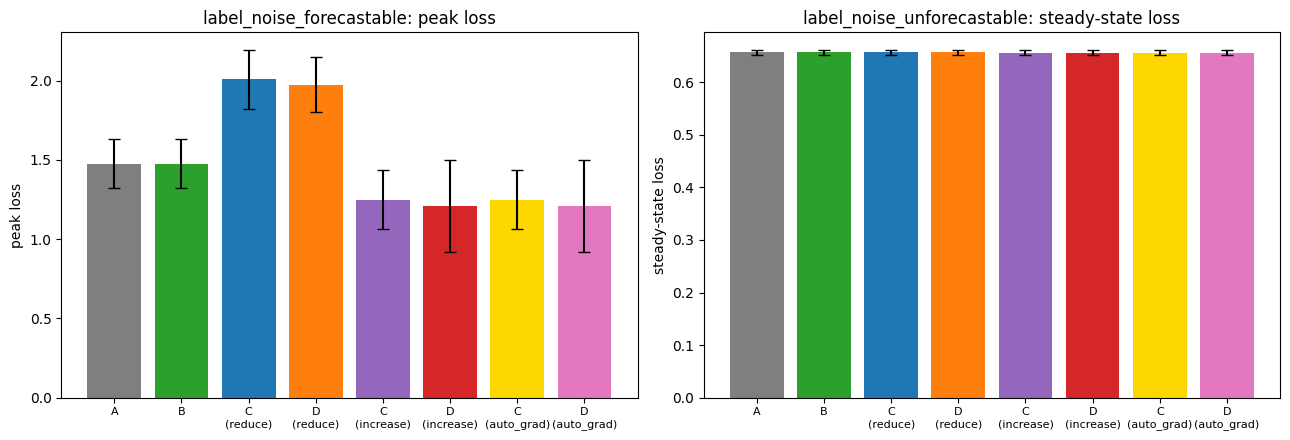

In [10]:
colors = {("A","n/a"):"tab:gray", ("B","n/a"):"tab:green",
          ("C","reduce"):"tab:blue", ("D","reduce"):"tab:orange",
          ("C","increase"):"tab:purple", ("D","increase"):"tab:red",
          ("C","auto_grad"):"gold", ("D","auto_grad"):"tab:pink"}
bar_series = [("A","n/a"), ("B","n/a"), ("C","reduce"), ("D","reduce"),
              ("C","increase"), ("D","increase"), ("C","auto_grad"), ("D","auto_grad")]
bar_labels = [f"{a}" + (f"\n({t})" if t != "n/a" else "") for a, t in bar_series]
bar_colors = [colors[s] for s in bar_series]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
peak_means = [get("label_noise_forecastable", a, t, "mean_peak_loss") for a, t in bar_series]
peak_stds = [get("label_noise_forecastable", a, t, "std_peak_loss") for a, t in bar_series]
axes[0].bar(bar_labels, peak_means, yerr=peak_stds, color=bar_colors, capsize=4)
axes[0].set_title("label_noise_forecastable: peak loss")
axes[0].set_ylabel("peak loss")
axes[0].tick_params(axis="x", labelsize=8)

ss_means = [get("label_noise_unforecastable", a, t, "mean_steady_state_loss") for a, t in bar_series]
ss_stds = [get("label_noise_unforecastable", a, t, "std_steady_state_loss") for a, t in bar_series]
axes[1].bar(bar_labels, ss_means, yerr=ss_stds, color=bar_colors, capsize=4)
axes[1].set_title("label_noise_unforecastable: steady-state loss")
axes[1].set_ylabel("steady-state loss")
axes[1].tick_params(axis="x", labelsize=8)

plt.tight_layout()
plt.savefig("exp_label_noise_bars.png", dpi=120)
plt.show()


## 8. Interpretation

In [11]:
peak_reduce = get("label_noise_forecastable", "C", "reduce", "mean_peak_loss")
peak_increase = get("label_noise_forecastable", "C", "increase", "mean_peak_loss")
peak_auto = get("label_noise_forecastable", "C", "auto_grad", "mean_peak_loss")
peak_base = get("label_noise_forecastable", "A", "n/a", "mean_peak_loss")

ss_reduce = get("label_noise_unforecastable", "C", "reduce", "mean_steady_state_loss")
ss_increase = get("label_noise_unforecastable", "C", "increase", "mean_steady_state_loss")
ss_auto = get("label_noise_unforecastable", "C", "auto_grad", "mean_steady_state_loss")
ss_base = get("label_noise_unforecastable", "A", "n/a", "mean_steady_state_loss")

peak_winner = "reduce" if peak_reduce < peak_increase else "increase"
ss_winner = "reduce" if ss_reduce < ss_increase else "increase"

# --- R2 (2026-08-26): re-score on CLEAN held-out loss instead of corrupted
# training-label loss. Domain review flagged that the original "increase wins"
# result may be an artifact of scoring against corrupted labels -- a metric a
# classifier can minimize by collapsing toward the noisy label distribution
# (predicting near 0.5, or drifting toward the flipped boundary) rather than by
# genuinely recovering the true decision boundary. The clean metric is computed
# on fresh, never-corrupted, never-trained-on batches every step and is immune
# to that failure mode.
clean_peak_reduce = get("label_noise_forecastable", "C", "reduce", "mean_clean_peak_loss")
clean_peak_increase = get("label_noise_forecastable", "C", "increase", "mean_clean_peak_loss")
clean_peak_auto = get("label_noise_forecastable", "C", "auto_grad", "mean_clean_peak_loss")
clean_peak_base = get("label_noise_forecastable", "A", "n/a", "mean_clean_peak_loss")

clean_ss_reduce = get("label_noise_unforecastable", "C", "reduce", "mean_clean_steady_state_loss")
clean_ss_increase = get("label_noise_unforecastable", "C", "increase", "mean_clean_steady_state_loss")
clean_ss_auto = get("label_noise_unforecastable", "C", "auto_grad", "mean_clean_steady_state_loss")
clean_ss_base = get("label_noise_unforecastable", "A", "n/a", "mean_clean_steady_state_loss")

clean_peak_winner = "reduce" if clean_peak_reduce < clean_peak_increase else "increase"
clean_ss_winner = "reduce" if clean_ss_reduce < clean_ss_increase else "increase"

peak_agrees = (peak_winner == clean_peak_winner)
ss_agrees = (ss_winner == clean_ss_winner)

n_triggered_grad = len(auto_rows)
n_correct_grad = int((auto_rows["active_intervention"] == "reduce").sum())
grad_acc = n_correct_grad / n_triggered_grad if n_triggered_grad else float("nan")

interpretation = f'''
LABEL NOISE (pure per-batch label flips, no drift, no input-variance change):

--- Scored on CORRUPTED training-batch loss (original R1-era metric) ---
Peak loss (forecastable):    A(base)={peak_base:.3f}  reduce={peak_reduce:.3f}  increase={peak_increase:.3f}  auto_grad={peak_auto:.3f}
Steady-state (unforecastable): A(base)={ss_base:.4f}  reduce={ss_reduce:.4f}  increase={ss_increase:.4f}  auto_grad={ss_auto:.4f}
VERDICT (corrupted-label metric): peak-loss winner = {peak_winner}, steady-state winner = {ss_winner}.

--- Scored on CLEAN held-out loss (R2 fix: independent fresh flip_prob=0 batch every step) ---
Peak loss (forecastable):    A(base)={clean_peak_base:.3f}  reduce={clean_peak_reduce:.3f}  increase={clean_peak_increase:.3f}  auto_grad={clean_peak_auto:.3f}
Steady-state (unforecastable): A(base)={clean_ss_base:.4f}  reduce={clean_ss_reduce:.4f}  increase={clean_ss_increase:.4f}  auto_grad={clean_ss_auto:.4f}
VERDICT (clean metric): peak-loss winner = {clean_peak_winner}, steady-state winner = {clean_ss_winner}.

AGREEMENT CHECK: peak-loss winner {"AGREES" if peak_agrees else "REVERSES"} between corrupted-label and clean scoring.
                  steady-state winner {"AGREES" if ss_agrees else "REVERSES"} between corrupted-label and clean scoring.

auto_grad diagnosis: chose "reduce" in {n_correct_grad}/{n_triggered_grad} triggered runs ({grad_acc*100:.0f}%).

{"R2 RESULT: the corrupted-label-metric winner is CONFIRMED on the clean held-out metric -- the original finding was not an artifact of scoring against corrupted labels." if (peak_agrees and ss_agrees) else "R2 RESULT: the corrupted-label-metric winner does NOT fully survive re-scoring on clean held-out data -- at least one of the peak-loss / steady-state verdicts flips when the confound (a classifier can lower corrupted-label loss by collapsing toward the noisy label distribution, not by recovering the true boundary) is removed. This means the original 'increase/reduce wins for label noise' claim as stated was partly or wholly a scoring artifact and must be restated in terms of the clean metric, per Domain reviewer's Critical finding."}

{"CONFIRMED: reduce wins for label noise too, on both corrupted-label metrics -- the earlier gradient-noise-injection finding was NOT mechanism-specific. Two structurally different ways of corrupting the learning signal (direct gradient noise vs. corrupted labels) both produce the same qualitative pattern: instability of ANY kind wants stabilization (reduce), while genuine task change (drift) wants faster relearning (increase)." if (peak_winner == "reduce" and ss_winner == "reduce") else "NOT confirmed as cleanly as gradient-noise instability was on the corrupted-label metrics -- label noise does not show the same clear reduce-wins pattern on both metrics there."}

auto_grad's diagnosis on this NEW mechanism it was never designed around: {"it correctly identified label noise as needing 'reduce' most of the time, suggesting the gradient-norm-vs-loss-elevation signature generalizes beyond the specific gradient-injection construction it was built and tuned on." if grad_acc > 0.7 else "it did NOT reliably identify label noise as instability -- the gradient-norm-elevation signature that worked for direct gradient-noise injection does not clearly transfer to this different corruption mechanism, which is an important boundary on how far auto_grad generalizes."}

This remains a qualitative check (n={len(SEEDS)} seeds, no pre-registered effect sizes,
same Stage A caveats as all prior notebooks this session) -- but the clean-vs-corrupted
comparison directly tests whether the headline "increase/reduce wins" claim for label
noise was a genuine training-dynamics effect or an artifact of the scoring metric used
to declare a winner (Domain reviewer Critical finding, R2 in the revision roadmap).
'''
print(interpretation)



LABEL NOISE (pure per-batch label flips, no drift, no input-variance change):

--- Scored on CORRUPTED training-batch loss (original R1-era metric) ---
Peak loss (forecastable):    A(base)=1.476  reduce=2.007  increase=1.248  auto_grad=1.248
Steady-state (unforecastable): A(base)=0.6564  reduce=0.6565  increase=0.6562  auto_grad=0.6562
VERDICT (corrupted-label metric): peak-loss winner = increase, steady-state winner = increase.

--- Scored on CLEAN held-out loss (R2 fix: independent fresh flip_prob=0 batch every step) ---
Peak loss (forecastable):    A(base)=0.541  reduce=0.537  increase=0.543  auto_grad=0.543
Steady-state (unforecastable): A(base)=0.4617  reduce=0.4596  increase=0.4634  auto_grad=0.4634
VERDICT (clean metric): peak-loss winner = reduce, steady-state winner = reduce.

AGREEMENT CHECK: peak-loss winner REVERSES between corrupted-label and clean scoring.
                  steady-state winner REVERSES between corrupted-label and clean scoring.

auto_grad diagnosis: chos